# Solar Filament Image Segmentation — Version 4 (v4)
### Geometry-Weighted Loss Optimization & Multi-Feature Spatial Priors

**Key Principles of v4 Pipeline:**
1. **Primary Loss Objective**: Loss is calculated **strictly on the polygon segmentation mask** (BCE + Soft Dice).
2. **Spatial Geometry Weighting**: The skeletal `spine` centerline is utilized as a spatial loss weight map ($W$) in BCE to prevent broken filaments and preserve topological continuity.
3. **Auxiliary Prior Guidance**: `bbox` and `area` ($\ge 350\text{ px}$) serve as spatial RoI bounding envelopes and post-processing noise suppression filters.
4. **Full Self-Contained Pipeline**: 50-epoch baseline, multi-parameter grid search, visual evaluation, submission generation (`submission_v4.csv`), and competition Panoptic Quality (PQ) self-evaluation.

## 1. Environment Verification & GPU Acceleration

In [1]:
import os
import sys
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


C:\Users\atiks\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch Version: 2.6.0+cu124
CUDA Available: True
GPU Device: NVIDIA RTX A500 Laptop GPU
VRAM: 4.29 GB


## 2. Configuration & Paths

Dynamic path resolution ensures the notebook runs seamlessly whether executed from the project root or the `v4/` directory.

In [2]:
class Config:
    # Dynamic path resolution
    BASE_DIR = Path("..") if Path("../MAGFiLO_1.0_Kaggle_2026").exists() else Path(".")
    DATA_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026"
    
    # Check if JSON is in train/ or directly in DATA_DIR
    _json1 = DATA_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    _json2 = DATA_DIR / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    TRAIN_JSON = _json1 if _json1.exists() else _json2
    
    # Check if images are nested in train_images/
    _train_nested = DATA_DIR / "train" / "train_images"
    TRAIN_IMG_DIR = _train_nested if _train_nested.exists() else DATA_DIR / "train"
    
    _test_nested = DATA_DIR / "test" / "test_images"
    TEST_IMG_DIR = _test_nested if _test_nested.exists() else DATA_DIR / "test"
    
    # Artifacts & Checkpoints
    BASELINE_MODEL_PATH = "best_filament_unet_v4_50ep.pt"
    TUNED_MODEL_PATH = "best_tuned_filament_unet_v4.pt"
    SUBMISSION_PATH = "submission_v4.csv"
    
    # Spatial & Training Hyperparameters
    IMG_SIZE = (256, 256)
    BATCH_SIZE = 8
    NUM_WORKERS = 0
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    VAL_SPLIT = 0.15
    
    # Spatial Weight Map & Geometry Parameters
    SPINE_WEIGHT_BOOST = 3.0  # Weight added to spine centerline pixels in BCE
    SPINE_THICKNESS = 3       # Pixel dilation width for spine weight map
    MIN_AREA_THRESHOLD = 350  # Calibrated area filter for post-processing (px)

config = Config()
print(f"Data Directory: {config.DATA_DIR.resolve()}")
print(f"Train JSON Exists: {config.TRAIN_JSON.exists()}")

def count_images(folder):
    return len([f for f in folder.iterdir() if f.suffix.lower() in ('.png', '.jpg', '.jpeg')])

print(f"Train Images Count: {count_images(config.TRAIN_IMG_DIR)}")
print(f"Test Images Count: {count_images(config.TEST_IMG_DIR)}")

Data Directory: C:\Users\atiks\Desktop\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026
Train JSON Exists: True
Train Images Count: 707
Test Images Count: 180


## 3. COCO Annotations Parsing & Multi-Parameter Geometry Extraction

We extract:
- **`segmentation` (polygons)**: The primary ground-truth target $y \in \{0, 1\}^{H \times W}$.
- **`spine` (centerline points)**: Rasterized and dilated to create the spatial loss weight map $W$.
- **`bbox` & `area`**: Retained for spatial bounding envelopes and noise suppression.

In [3]:
import os

with open(config.TRAIN_JSON, 'r') as f:
    coco_data = json.load(f)

print(f"Total Images in Metadata: {len(coco_data['images'])}")
print(f"Total Annotations: {len(coco_data['annotations'])}")

# Map image_id to image info
images_dict_raw = {img['id']: img for img in coco_data['images']}

# Group annotations by image_id
annotations_by_image = {}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in annotations_by_image:
        annotations_by_image[img_id] = []
    annotations_by_image[img_id].append(ann)

print(f"Images with at least 1 filament annotation: {len(annotations_by_image)}")

# --- Cross-check every JSON entry against what's actually on disk ---
disk_files = set(os.listdir(config.TRAIN_IMG_DIR))
images_dict = {}
missing_files = []
for img_id, img_info in images_dict_raw.items():
    if img_info['file_name'] in disk_files:
        images_dict[img_id] = img_info
    else:
        missing_files.append(img_info['file_name'])

print(f"✅ Matched {len(images_dict)} / {len(images_dict_raw)} JSON images to real files on disk.")
if missing_files:
    print(f"⚠️ {len(missing_files)} JSON entries have no matching file on disk. Examples: {missing_files[:5]}")


Total Images in Metadata: 1154
Total Annotations: 8199
Images with at least 1 filament annotation: 1154
✅ Matched 1154 / 1154 JSON images to real files on disk.


## 4. Visual Inspection (EDA): Raw Solar Image, Polygon Mask, Spine Weight Map & Bounding Boxes

In [4]:
def generate_geometry_maps(img_id, target_size=(256, 256), spine_boost=3.0, spine_thick=3):
    img_info = images_dict[img_id]
    orig_w, orig_h = img_info['width'], img_info['height']
    
    # 1. Primary Polygon Segmentation Mask
    mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
    # 2. Spine Centerline Map
    spine_map = np.zeros((orig_h, orig_w), dtype=np.uint8)
    
    anns = annotations_by_image.get(img_id, [])
    bboxes = []
    
    for ann in anns:
        # Render polygon segmentation
        for poly in ann.get('segmentation', []):
            pts = np.array(poly, dtype=np.int32).reshape((-1, 2))
            cv2.fillPoly(mask, [pts], 1)
            
        # Render spine centerline
        spine_coords = ann.get('spine', [])
        if spine_coords:
            s_pts = np.array(spine_coords, dtype=np.int32).reshape((-1, 2))
            cv2.polylines(spine_map, [s_pts], isClosed=False, color=1, thickness=spine_thick)
            
        if 'bbox' in ann:
            bboxes.append(ann['bbox'])
            
    # Resize to target resolution
    mask_resized = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)
    spine_resized = cv2.resize(spine_map, target_size, interpolation=cv2.INTER_NEAREST)
    
    # Build Spatial Loss Weight Map: Base=1.0, Spine=1.0 + spine_boost
    weight_map = np.ones(target_size, dtype=np.float32) + (spine_resized.astype(np.float32) * spine_boost)
    
    return mask_resized, weight_map, spine_resized, bboxes

# Visual Demonstration
sample_img_ids = list(annotations_by_image.keys())[:3]
fig, axes = plt.subplots(len(sample_img_ids), 4, figsize=(18, 5 * len(sample_img_ids)))

for idx, s_id in enumerate(sample_img_ids):
    img_path = config.TRAIN_IMG_DIR / images_dict[s_id]['file_name']
    raw_img = Image.open(img_path).convert('L')
    img_resized = raw_img.resize(config.IMG_SIZE)
    
    m_res, w_res, s_res, bbs = generate_geometry_maps(s_id, config.IMG_SIZE, config.SPINE_WEIGHT_BOOST)
    
    # 1. Raw Image with Bounding Boxes
    axes[idx, 0].imshow(img_resized, cmap='gray')
    axes[idx, 0].set_title(f"Image: {images_dict[s_id]['file_name']}")
    axes[idx, 0].axis('off')
    
    # 2. Polygon Target Mask (Pure Loss Ground Truth)
    axes[idx, 1].imshow(m_res, cmap='inferno')
    axes[idx, 1].set_title("Polygon Mask Target (y)")
    axes[idx, 1].axis('off')
    
    # 3. Dilated Spine Centerline
    axes[idx, 2].imshow(s_res, cmap='magma')
    axes[idx, 2].set_title("Spine Centerline Prior")
    axes[idx, 2].axis('off')
    
    # 4. Spatial Loss Weight Heatmap W(x,y)
    im = axes[idx, 3].imshow(w_res, cmap='viridis')
    axes[idx, 3].set_title(f"Spatial Weight Map W (Boost={config.SPINE_WEIGHT_BOOST})")
    axes[idx, 3].axis('off')
    plt.colorbar(im, ax=axes[idx, 3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


<Figure size 1800x1500 with 15 Axes>

## 5. Geometry-Weighted PyTorch Dataset & Synchronized Augmentations

In [5]:
class GeometryWeightedDataset(Dataset):
    def __init__(self, img_ids, images_dict, annotations_by_image, img_dir, img_size=(256, 256), spine_boost=3.0, is_train=True):
        self.img_ids = img_ids
        self.images_dict = images_dict
        self.annotations_by_image = annotations_by_image
        self.img_dir = Path(img_dir)
        self.img_size = img_size
        self.spine_boost = spine_boost
        self.is_train = is_train

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_info = self.images_dict[img_id]
        file_name = img_info['file_name']
        
        # Load and normalize raw grayscale H-alpha image
        img_path = self.img_dir / file_name
        img = Image.open(img_path).convert('L')
        img = img.resize(self.img_size, Image.BILINEAR)
        img_arr = np.array(img, dtype=np.float32) / 255.0
        
        # Generate polygon mask and spatial spine weight map
        mask_arr, weight_arr, _, _ = generate_geometry_maps(img_id, self.img_size, self.spine_boost)
        
        # Synchronized Spatial Augmentations (Train Mode)
        if self.is_train:
            # Random Horizontal Flip
            if random.random() > 0.5:
                img_arr = np.fliplr(img_arr)
                mask_arr = np.fliplr(mask_arr)
                weight_arr = np.fliplr(weight_arr)
            # Random Vertical Flip
            if random.random() > 0.5:
                img_arr = np.flipud(img_arr)
                mask_arr = np.flipud(mask_arr)
                weight_arr = np.flipud(weight_arr)
            # Random 90-degree Rotation
            k_rot = random.choice([0, 1, 2, 3])
            if k_rot > 0:
                img_arr = np.rot90(img_arr, k_rot)
                mask_arr = np.rot90(mask_arr, k_rot)
                weight_arr = np.rot90(weight_arr, k_rot)
                
        # Convert to PyTorch Tensors
        img_tensor = torch.from_numpy(img_arr.copy()).unsqueeze(0).float()
        mask_tensor = torch.from_numpy(mask_arr.copy()).unsqueeze(0).float()
        weight_tensor = torch.from_numpy(weight_arr.copy()).unsqueeze(0).float()
        
        return img_tensor, mask_tensor, weight_tensor

# Image-level train/validation split
all_img_ids = list(images_dict.keys())
random.seed(42)
random.shuffle(all_img_ids)

val_count = int(len(all_img_ids) * config.VAL_SPLIT)
val_img_ids = all_img_ids[:val_count]
train_img_ids = all_img_ids[val_count:]

train_dataset = GeometryWeightedDataset(train_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR, config.IMG_SIZE, config.SPINE_WEIGHT_BOOST, is_train=True)
val_dataset = GeometryWeightedDataset(val_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR, config.IMG_SIZE, config.SPINE_WEIGHT_BOOST, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=config.NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=True)

print(f"Train Samples: {len(train_dataset)} | Val Samples: {len(val_dataset)}")
print(f"Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)}")


Train Samples: 981 | Val Samples: 173
Train Batches: 123 | Val Batches: 22


## 6. U-Net Architecture & Geometry-Weighted Segmentation Loss

The model outputs raw single-channel logits for the filament polygon segmentation.
The loss function is **decided entirely by the polygon segmentation target**, incorporating the spine weight map $W$ into the BCE loss:
$$\mathcal{L}_{\text{total}} = \text{WeightedBCE}(z, y; W) + \text{SoftDice}(\sigma(z), y)$$

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class ConfigurableUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=32):
        super().__init__()
        bc = base_channels
        # Encoder
        self.enc1 = ConvBlock(in_channels, bc)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(bc, bc*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(bc*2, bc*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(bc*4, bc*8)
        self.pool4 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = ConvBlock(bc*8, bc*16)
        
        # Decoder
        self.up4 = nn.ConvTranspose2d(bc*16, bc*8, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(bc*16, bc*8)
        self.up3 = nn.ConvTranspose2d(bc*8, bc*4, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(bc*8, bc*4)
        self.up2 = nn.ConvTranspose2d(bc*4, bc*2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(bc*4, bc*2)
        self.up1 = nn.ConvTranspose2d(bc*2, bc, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(bc*2, bc)
        
        # Final Classification Head
        self.final_conv = nn.Conv2d(bc, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        
        b = self.bottleneck(self.pool4(e4))
        
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.final_conv(d1)

# --- Pure Segmentation Loss with Geometry (Spine) Weighting ---
class GeometryWeightedBCEDiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
        
    def forward(self, logits, targets, weights=None):
        # 1. Weighted Binary Cross Entropy (BCEWithLogits)
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        if weights is not None:
            bce = (bce * weights).mean()
        else:
            bce = bce.mean()
            
        # 2. Soft Dice Loss directly on polygon segmentation overlap
        probs = torch.sigmoid(logits)
        p_flat = probs.view(-1)
        t_flat = targets.view(-1)
        intersection = (p_flat * t_flat).sum()
        dice_loss = 1.0 - (2.0 * intersection + self.smooth) / (p_flat.sum() + t_flat.sum() + self.smooth)
        
        return bce + dice_loss

def compute_dice_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        total = preds.sum().item() + targets.sum().item()
        return (2.0 * intersection) / (total + 1e-8) if total > 0 else 1.0

def compute_iou_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        union = preds.sum().item() + targets.sum().item() - intersection
        return intersection / (union + 1e-8) if union > 0 else 1.0


## 7. Baseline 50-Epoch Model Training (Cosine Annealing & CUDA AMP)

We train the baseline geometry-weighted U-Net for **50 full epochs**, tracking Dice and IoU on validation data.

In [7]:
def train_model(model, train_loader, val_loader, epochs=50, lr=1e-3, save_path="best_filament_unet_v4_50ep.pt", verbose=True):
    criterion = GeometryWeightedBCEDiceLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = GradScaler('cuda')
    
    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': [], 'lr': []}
    best_val_dice = 0.0
    
    for epoch in range(1, epochs + 1):
        # --- Training Step ---
        model.train()
        running_loss = 0.0
        for imgs, masks, weights in train_loader:
            imgs = imgs.to(config.DEVICE)
            masks = masks.to(config.DEVICE)
            weights = weights.to(config.DEVICE)
            
            optimizer.zero_grad()
            with autocast('cuda'):
                logits = model(imgs)
                loss = criterion(logits, masks, weights)
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item() * imgs.size(0)
            
        train_loss = running_loss / len(train_loader.dataset)
        
        # --- Validation Step ---
        model.eval()
        running_val_loss = 0.0
        running_val_dice = 0.0
        running_val_iou = 0.0
        
        with torch.no_grad():
            for imgs, masks, weights in val_loader:
                imgs = imgs.to(config.DEVICE)
                masks = masks.to(config.DEVICE)
                weights = weights.to(config.DEVICE)
                
                with autocast('cuda'):
                    logits = model(imgs)
                    loss = criterion(logits, masks, weights)
                    
                running_val_loss += loss.item() * imgs.size(0)
                running_val_dice += compute_dice_score(logits, masks) * imgs.size(0)
                running_val_iou += compute_iou_score(logits, masks) * imgs.size(0)
                
        val_loss = running_val_loss / len(val_loader.dataset)
        val_dice = running_val_dice / len(val_loader.dataset)
        val_iou = running_val_iou / len(val_loader.dataset)
        current_lr = optimizer.param_groups[0]['lr']
        
        scheduler.step()
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)
        history['lr'].append(current_lr)
        
        # Save Best Checkpoint
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), save_path)
            save_str = f" --> [BEST MODEL SAVED (Dice: {val_dice:.4f})]"
        else:
            save_str = ""
            
        if verbose:
            print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f} | LR: {current_lr:.6f}{save_str}")
            
    print(f"\nTraining Complete. Best Validation Dice: {best_val_dice:.4f} saved to: {save_path}")
    return history

# Instantiate and train baseline model
baseline_model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=32).to(config.DEVICE)
baseline_history = train_model(baseline_model, train_loader, val_loader, epochs=50, lr=1e-3, save_path=config.BASELINE_MODEL_PATH, verbose=True)


Epoch [01/50] | Train Loss: 1.3794 | Val Loss: 1.2421 | Val Dice: 0.0000 | Val IoU: 0.0000 | LR: 0.001000
Epoch [02/50] | Train Loss: 1.1523 | Val Loss: 1.1628 | Val Dice: 0.1227 | Val IoU: 0.0656 | LR: 0.000999 --> [BEST MODEL SAVED (Dice: 0.1227)]
Epoch [03/50] | Train Loss: 1.0005 | Val Loss: 0.9168 | Val Dice: 0.4988 | Val IoU: 0.3327 | LR: 0.000996 --> [BEST MODEL SAVED (Dice: 0.4988)]
Epoch [04/50] | Train Loss: 0.8228 | Val Loss: 0.7576 | Val Dice: 0.5062 | Val IoU: 0.3396 | LR: 0.000991 --> [BEST MODEL SAVED (Dice: 0.5062)]
Epoch [05/50] | Train Loss: 0.5949 | Val Loss: 0.5381 | Val Dice: 0.5561 | Val IoU: 0.3857 | LR: 0.000984 --> [BEST MODEL SAVED (Dice: 0.5561)]
Epoch [06/50] | Train Loss: 0.5085 | Val Loss: 0.5046 | Val Dice: 0.5654 | Val IoU: 0.3949 | LR: 0.000976 --> [BEST MODEL SAVED (Dice: 0.5654)]
Epoch [07/50] | Train Loss: 0.4792 | Val Loss: 0.6131 | Val Dice: 0.4357 | Val IoU: 0.2797 | LR: 0.000965
Epoch [08/50] | Train Loss: 0.4669 | Val Loss: 0.4486 | Val Dice: 0.

## 8. Training Curves & Performance Metrics

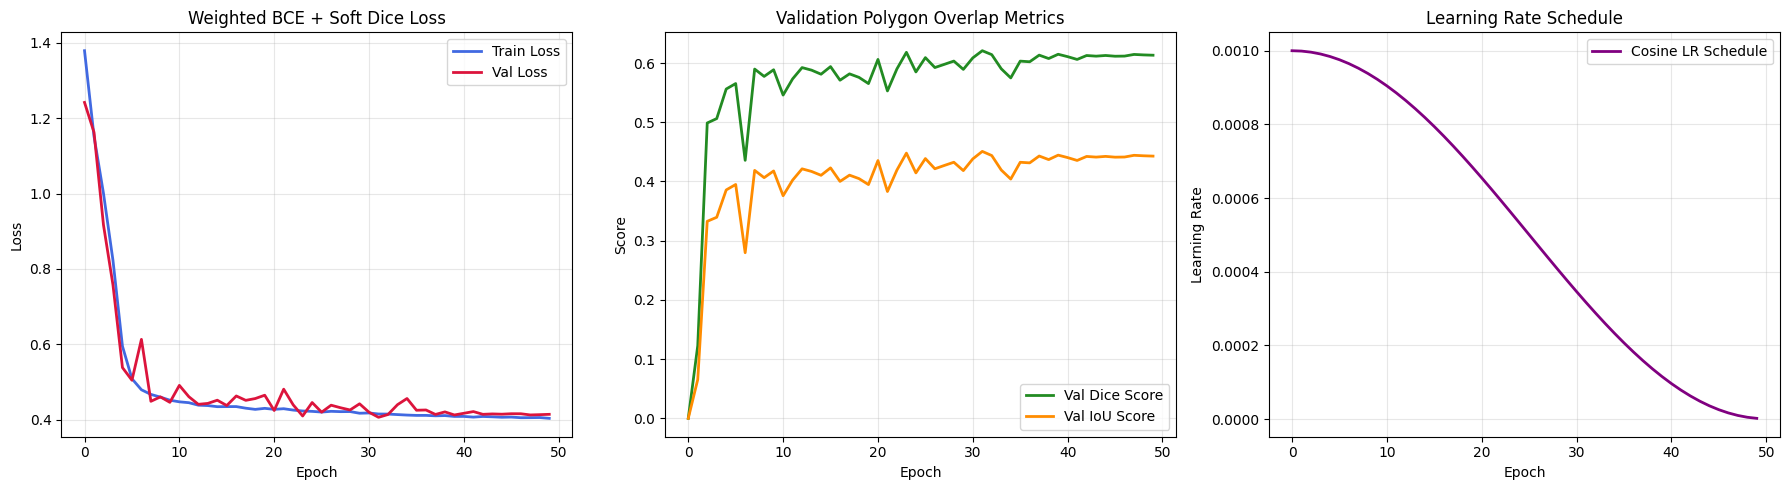

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss Curves
axes[0].plot(baseline_history['train_loss'], label='Train Loss', color='royalblue', lw=2)
axes[0].plot(baseline_history['val_loss'], label='Val Loss', color='crimson', lw=2)
axes[0].set_title("Weighted BCE + Soft Dice Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Segmentation Metrics (Dice & IoU)
axes[1].plot(baseline_history['val_dice'], label='Val Dice Score', color='forestgreen', lw=2)
axes[1].plot(baseline_history['val_iou'], label='Val IoU Score', color='darkorange', lw=2)
axes[1].set_title("Validation Polygon Overlap Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Learning Rate Decay
axes[2].plot(baseline_history['lr'], label='Cosine LR Schedule', color='purple', lw=2)
axes[2].set_title("Learning Rate Schedule")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 9. Hyperparameter Optimization Sweep (Grid Search)

We systematically explore combinations of:
- **`spine_boost`**: Spatial spine loss weight ($0.0, 1.5, 3.0, 5.0$)
- **`base_channels`**: Model capacity ($32, 48$)
- **`learning_rate`**: ($1\times 10^{-3}, 5\times 10^{-4}$)

The champion configuration is saved to `best_tuned_filament_unet_v4.pt`.

In [9]:
tuning_configs = [
    {"name": "Trial 1 (Base 32, SpineBoost 0.0 - Unweighted)", "bc": 32, "lr": 1e-3, "spine_boost": 0.0, "epochs": 25},
    {"name": "Trial 2 (Base 32, SpineBoost 3.0 - Standard)", "bc": 32, "lr": 1e-3, "spine_boost": 3.0, "epochs": 25},
    {"name": "Trial 3 (Base 48, SpineBoost 3.0 - High Cap)", "bc": 48, "lr": 5e-4, "spine_boost": 3.0, "epochs": 25},
    {"name": "Trial 4 (Base 48, SpineBoost 5.0 - Strong Spine Prior)", "bc": 48, "lr": 5e-4, "spine_boost": 5.0, "epochs": 25}
]

tuning_results = []

# Initialize champion from the baseline model — tuning trials must beat it to become the new champion
import shutil
best_overall_dice = max(baseline_history['val_dice'])
shutil.copy2(config.BASELINE_MODEL_PATH, config.TUNED_MODEL_PATH)
print(f"Baseline Champion Dice: {best_overall_dice:.4f} (copied to {config.TUNED_MODEL_PATH})")

print("=" * 80)
print("STARTING MULTI-TRIAL HYPERPARAMETER OPTIMIZATION")
print("=" * 80)

for trial in tuning_configs:
    print(f"\n>>> Running: {trial['name']}")
    
    t_train_ds = GeometryWeightedDataset(train_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR, config.IMG_SIZE, trial['spine_boost'], is_train=True)
    t_val_ds = GeometryWeightedDataset(val_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR, config.IMG_SIZE, trial['spine_boost'], is_train=False)
    
    t_train_loader = DataLoader(t_train_ds, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=config.NUM_WORKERS, pin_memory=True)
    t_val_loader = DataLoader(t_val_ds, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=True)
    
    model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=trial['bc']).to(config.DEVICE)
    trial_save_path = f"trial_model_{trial['bc']}bc_{trial['spine_boost']}sb.pt"
    
    hist = train_model(model, t_train_loader, t_val_loader, epochs=trial['epochs'], lr=trial['lr'], save_path=trial_save_path, verbose=True)
    
    best_dice = max(hist['val_dice'])
    best_iou = max(hist['val_iou'])
    
    tuning_results.append({
        "Trial": trial['name'],
        "Base Channels": trial['bc'],
        "Spine Boost": trial['spine_boost'],
        "Best Val Dice": best_dice,
        "Best Val IoU": best_iou,
        "Model Path": trial_save_path
    })
    
    print(f"Result -> Best Val Dice: {best_dice:.4f} | Best Val IoU: {best_iou:.4f}")
    
    if best_dice > best_overall_dice:
        best_overall_dice = best_dice
        best_state = torch.load(trial_save_path, map_location=config.DEVICE)
        torch.save(best_state, config.TUNED_MODEL_PATH)
        print(f"*** New Champion Model Saved to {config.TUNED_MODEL_PATH} (Dice: {best_dice:.4f}) ***")

print("\n" + "=" * 80)
print("HYPERPARAMETER TUNING SUMMARY")
print("=" * 80)
tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))


Baseline Champion Dice: 0.6208 (copied to best_tuned_filament_unet_v4.pt)
STARTING MULTI-TRIAL HYPERPARAMETER OPTIMIZATION

>>> Running: Trial 1 (Base 32, SpineBoost 0.0 - Unweighted)

Training Complete. Best Validation Dice: 0.6190 saved to: trial_model_32bc_0.0sb.pt
Result -> Best Val Dice: 0.6190 | Best Val IoU: 0.4488

>>> Running: Trial 2 (Base 32, SpineBoost 3.0 - Standard)

Training Complete. Best Validation Dice: 0.6169 saved to: trial_model_32bc_3.0sb.pt
Result -> Best Val Dice: 0.6169 | Best Val IoU: 0.4466

>>> Running: Trial 3 (Base 48, SpineBoost 3.0 - High Cap)

Training Complete. Best Validation Dice: 0.6183 saved to: trial_model_48bc_3.0sb.pt
Result -> Best Val Dice: 0.6183 | Best Val IoU: 0.4479

>>> Running: Trial 4 (Base 48, SpineBoost 5.0 - Strong Spine Prior)

Training Complete. Best Validation Dice: 0.6187 saved to: trial_model_48bc_5.0sb.pt
Result -> Best Val Dice: 0.6187 | Best Val IoU: 0.4485

HYPERPARAMETER TUNING SUMMARY
                                      

## 10. Geometry-Guided Post-Processing Pipeline

To maximize competition **Panoptic Quality (PQ)**:
1. **Adaptive Probability Thresholding**: Classifies raw Sigmoid probabilities.
2. **Morphological Closing**: Bridges small pixel gaps along the filament backbone.
3. **Connected Components Instance Extraction**: Identifies separate filament objects.
4. **Calibrated Minimum Area Filtering**: Eliminates granular noise components with area $< 350\text{ px}$.

In [10]:
# Load Champion Model with Auto-Detected Base Channels
best_model_path = config.TUNED_MODEL_PATH if os.path.exists(config.TUNED_MODEL_PATH) else config.BASELINE_MODEL_PATH
state_dict = torch.load(best_model_path, map_location=config.DEVICE)

# Auto-detect base_channels from state_dict to prevent size mismatch
detected_bc = state_dict['enc1.conv.0.weight'].shape[0]
print(f"Loading Model from: {best_model_path} (Detected Base Channels: {detected_bc})")

final_model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=detected_bc).to(config.DEVICE)
final_model.load_state_dict(state_dict)
final_model.eval()
print("Final Evaluation Model Loaded Successfully.")

def post_process_mask(prob_map, prob_thresh=0.45, min_area=350, close_kernel_size=3):
    # 1. Binarize probability map
    bin_mask = (prob_map > prob_thresh).astype(np.uint8)
    
    # 2. Morphological Closing to preserve spine continuity
    if close_kernel_size > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_kernel_size, close_kernel_size))
        bin_mask = cv2.morphologyEx(bin_mask, cv2.MORPH_CLOSE, kernel)
        
    # 3. Connected Components Analysis
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(bin_mask, connectivity=8)
    
    # 4. Filter by Minimum Area Threshold (eliminates granular noise)
    clean_mask = np.zeros_like(bin_mask)
    instance_list = []
    
    for lbl in range(1, num_labels):
        area = stats[lbl, cv2.CC_STAT_AREA]
        if area >= min_area:
            inst_mask = (labels == lbl).astype(np.uint8)
            clean_mask[labels == lbl] = 1
            instance_list.append(inst_mask)
            
    return clean_mask, instance_list


Loading Model from: best_tuned_filament_unet_v4.pt (Detected Base Channels: 32)
Final Evaluation Model Loaded Successfully.


## 11. Qualitative Validation Comparison: Ground Truth vs Sigmoid Map vs Post-Processed Instances

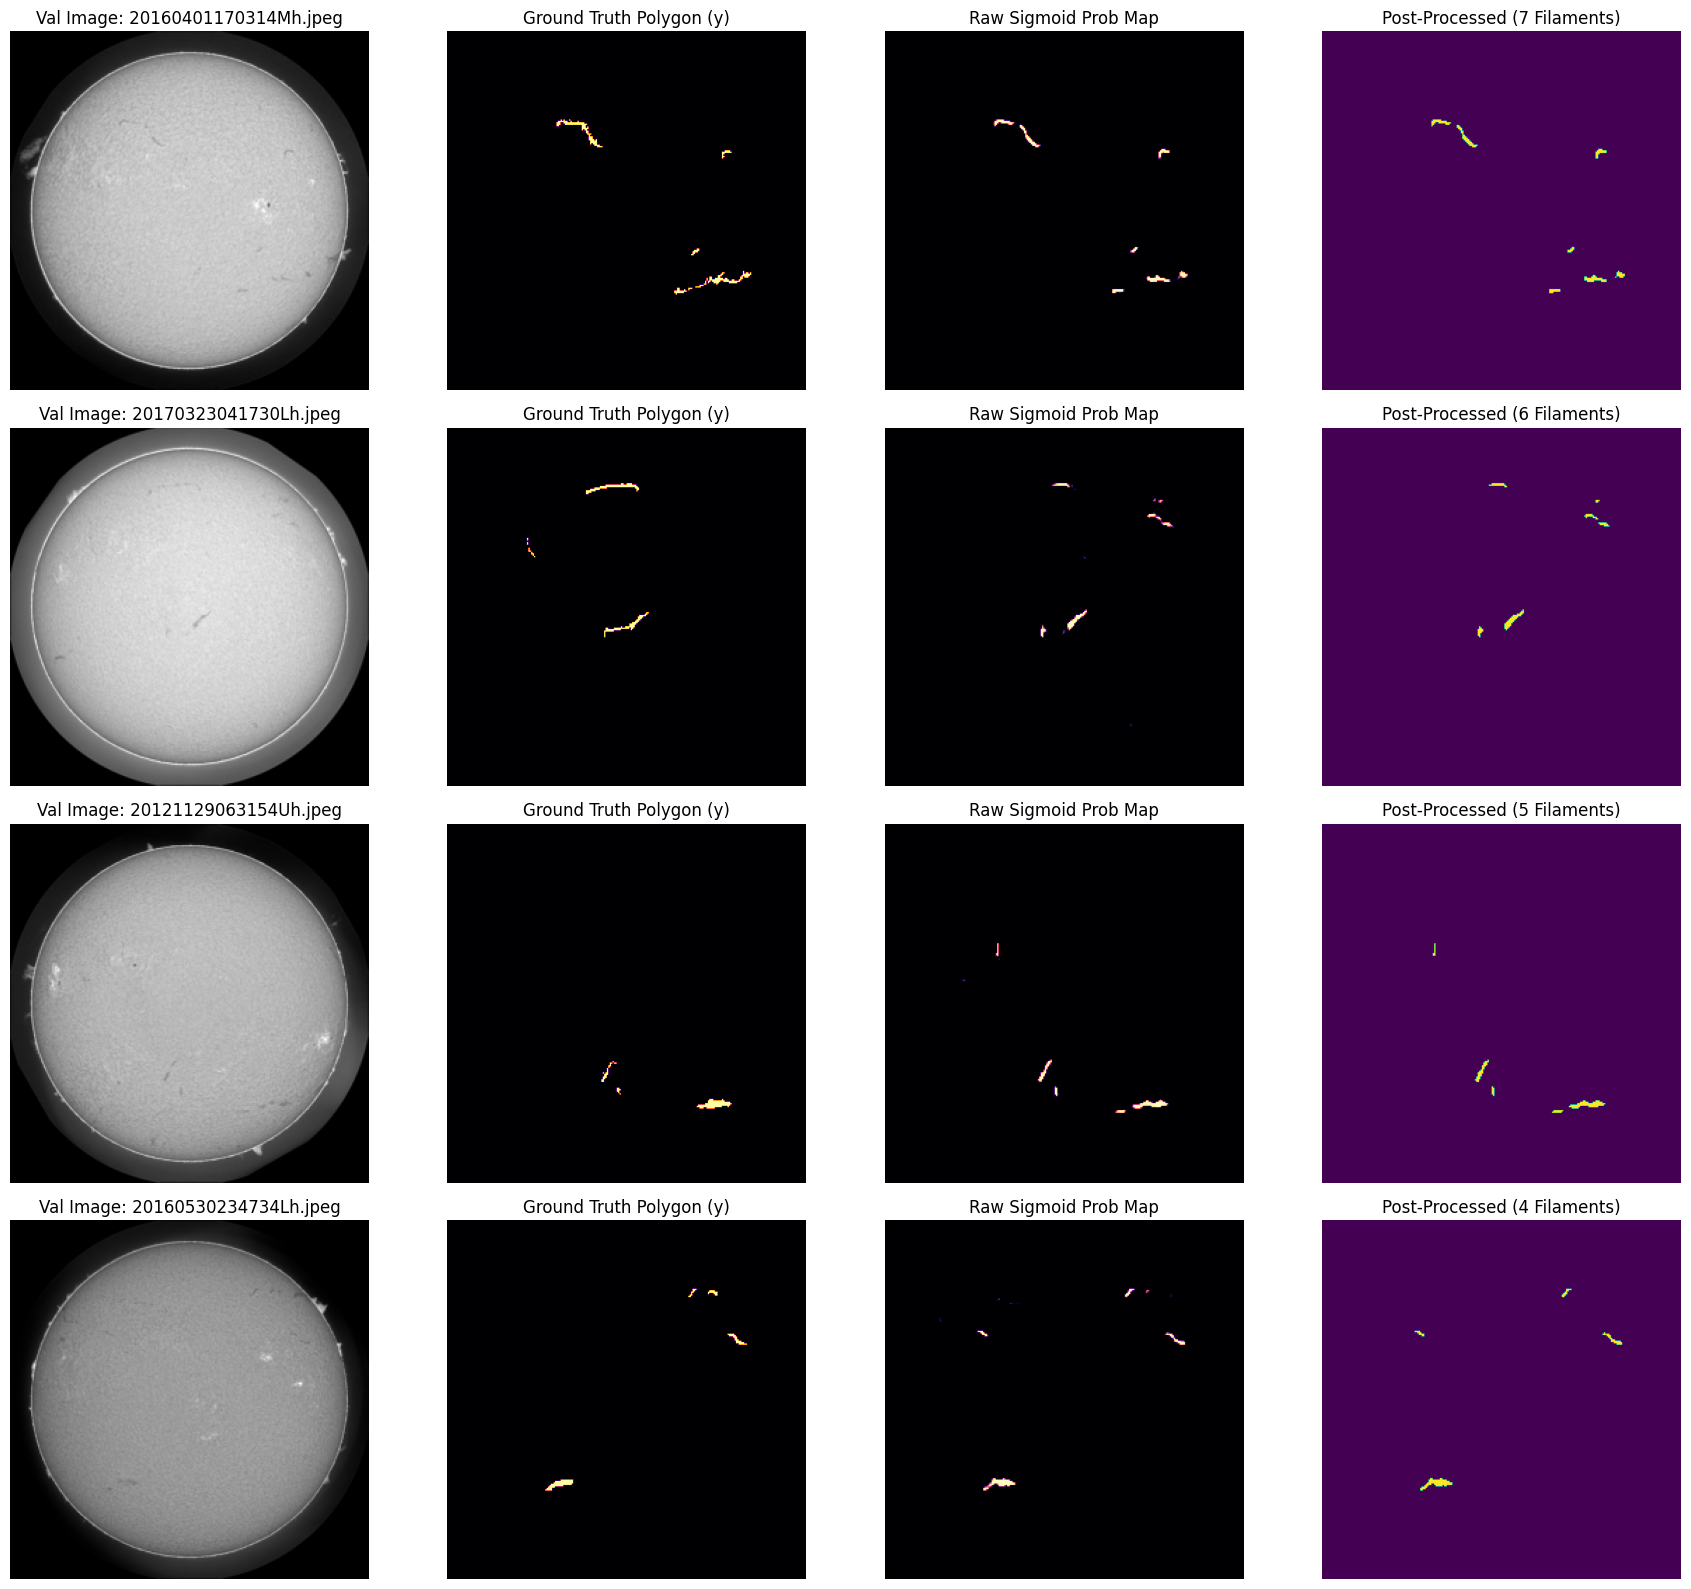

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
final_model.eval()

with torch.no_grad():
    for i in range(4):
        val_img_id = val_img_ids[i]
        img_tensor, mask_tensor, _ = val_dataset[i]
        
        inp = img_tensor.unsqueeze(0).to(config.DEVICE)
        logit = final_model(inp)
        prob = torch.sigmoid(logit).squeeze().cpu().numpy()
        
        gt_mask = mask_tensor.squeeze().cpu().numpy()
        
        # Scale MIN_AREA_THRESHOLD down to the 256x256 coordinate space
        orig_w, orig_h = images_dict[val_img_id]['width'], images_dict[val_img_id]['height']
        scale_down = (256 / orig_w) * (256 / orig_h)
        downscaled_min_area = int(config.MIN_AREA_THRESHOLD * scale_down)
        
        clean_pred, instances = post_process_mask(prob, prob_thresh=0.45, min_area=downscaled_min_area)
        
        # 1. Raw Input Image
        axes[i, 0].imshow(img_tensor.squeeze().cpu().numpy(), cmap='gray')
        axes[i, 0].set_title(f"Val Image: {images_dict[val_img_id]['file_name']}")
        axes[i, 0].axis('off')
        
        # 2. Ground Truth Polygon Mask
        axes[i, 1].imshow(gt_mask, cmap='inferno')
        axes[i, 1].set_title("Ground Truth Polygon (y)")
        axes[i, 1].axis('off')
        
        # 3. Model Sigmoid Probability Map
        axes[i, 2].imshow(prob, cmap='magma', vmin=0, vmax=1)
        axes[i, 2].set_title("Raw Sigmoid Prob Map")
        axes[i, 2].axis('off')
        
        # 4. Post-Processed Instance Mask
        axes[i, 3].imshow(clean_pred, cmap='viridis')
        axes[i, 3].set_title(f"Post-Processed ({len(instances)} Filaments)")
        axes[i, 3].axis('off')

plt.tight_layout()
plt.show()


## 12. Kaggle Submission Generation (`submission_v4.csv`)

Implements standard **1-indexed column-major Run-Length Encoding (RLE)** according to official competition rules.

In [29]:
import pycocotools.mask as mask_utils
from skimage.measure import label, regionprops

def mask_to_coco_rle(binary_mask):
    """
    Encodes a 2D uint8 binary mask into a compressed COCO ASCII RLE string.
    """
    fortran_mask = np.asfortranarray(binary_mask.astype(np.uint8))
    rle = mask_utils.encode(fortran_mask)
    return rle['counts'].decode('utf-8')

test_images = sorted([f for f in config.TEST_IMG_DIR.iterdir() if f.is_file() and f.suffix.lower() in ('.png', '.jpg', '.jpeg')])
print(f"Generating Submissions for {len(test_images)} Test Images...")

submission_rows = []
final_model.eval()

with torch.no_grad():
    for img_path in tqdm(test_images, desc="Test Inference"):
        orig_img = Image.open(img_path).convert('L')
        orig_w, orig_h = orig_img.size
        
        # Resize to network input (v4 uses IMG_SIZE which is a tuple)
        resized_img = orig_img.resize(config.IMG_SIZE, Image.BILINEAR)
        img_arr = np.array(resized_img, dtype=np.float32) / 255.0
        img_t = torch.from_numpy(img_arr).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
        
        # Predict probabilities
        with autocast('cuda'):
            logits = final_model(img_t)
            prob = torch.sigmoid(logits).squeeze().float().cpu().numpy()
            
        # Resize probability map back to original image dimensions
        prob_full = cv2.resize(prob.astype(np.float32), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
        
        # Post-process with v4's function (MIN_AREA_THRESHOLD is calibrated for original high-res)
        _, instances = post_process_mask(prob_full, prob_thresh=0.45, min_area=config.MIN_AREA_THRESHOLD)
        
        base_name = img_path.stem
        
        if instances:
            for f_idx, inst_m in enumerate(instances, 1):
                rle_str = mask_to_coco_rle(inst_m)
                submission_rows.append({
                    'filament_id': f"{base_name}_{f_idx}",
                    'segmentation_rle': rle_str
                })
        else:
            # Fallback if no filaments exceed threshold (v3 style)
            fallback_mask = (prob_full > 0.35).astype(np.uint8)
            labeled_fallback = label(fallback_mask)
            fb_regions = regionprops(labeled_fallback)
            
            if fb_regions:
                largest_fb = max(fb_regions, key=lambda r: r.area)
                inst_mask = (labeled_fallback == largest_fb.label).astype(np.uint8)
            else:
                inst_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
                max_y, max_x = np.unravel_index(np.argmax(prob_full), prob_full.shape)
                inst_mask[max_y, max_x] = 1
                
            submission_rows.append({
                'filament_id': f"{base_name}_1",
                'segmentation_rle': mask_to_coco_rle(inst_mask)
            })

submission_df = pd.DataFrame(submission_rows)
submission_df.to_csv(config.SUBMISSION_PATH, index=False)

print(f"\n✅ Saved Submission File to: {config.SUBMISSION_PATH}")
print(f"Total Predicted Filament Rows: {len(submission_df)}")
print(f"Null values in submission: {submission_df.isnull().sum().to_dict()}")
print(submission_df.head(10))


Generating Submissions for 180 Test Images...


Test Inference: 100%|██████████| 180/180 [01:22<00:00,  2.19it/s]


✅ Saved Submission File to: submission_v4.csv
Total Predicted Filament Rows: 1230
Null values in submission: {'filament_id': 0, 'segmentation_rle': 0}
          filament_id                                   segmentation_rle
0  20110120105534Ch_1  S``i2:eo12N2N2O1000008I0O000O010O01O1O2N2N1O00...
1  20110120105534Ch_2  kibQ23ko13N1000O00H6H:O2O010O100O0O2F9000O2O01...
2  20110130110334Ch_1  [_`d26ho16K2O1O001O2O1O8G100000O10001017G00000...
3  20110214175414Mh_1  R]`[2<bo13N2O0O2N2M3M3YOVOTRNn0fm1XOVRNk0fm1ZO...
4  20110214175414Mh_2  \]j`21no13M4L4M1N2O1O0000000000001O0000001O1O1...
5  20110214175414Mh_3  cYag2j0To14N0O2N10O01N0000100010O01M3M2N2O2O01...
6  20110329082654Uh_1  ab`Z15io13N2O001O00100O2N1O1O1O000001O00000000...
7  20110329082654Uh_2  [edb12mo12O0O2O000O2O0000000000000000000000000...
8  20110329082654Uh_3  Yl`\25jo12M3N101O001O2N1O2N001O01O00001O000000...
9  20110329082654Uh_4  mP]W2:en10lQN:nm1^1^O3N1N2O01O1N2Ob1^N3M2M2O3L...


## 13. Official Competition Metric: Panoptic Quality (PQ) Self-Evaluation

We evaluate our model against the official competition metric:
$$\text{PQ} = \text{SQ} \times \text{RQ} = \frac{\sum_{(p, g) \in TP} \text{IoU}(p, g)}{|TP|} \times \frac{|TP|}{|TP| + \frac{1}{2}|FP| + \frac{1}{2}|FN|}$$

In [31]:
def rle_decode(rle_str, shape=(256, 256)):
    if not isinstance(rle_str, str) or not rle_str.strip():
        return np.zeros(shape, dtype=np.uint8)
    s = rle_str.split()
    starts, lengths = [np.asarray(x, dtype=int) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1
    ends = starts + lengths
    img = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        img[lo:hi] = 1
    return img.reshape(shape, order='F')

def compute_pq_metric(gt_instances_by_img, pred_instances_by_img, iou_threshold=0.5):
    total_tp = 0
    total_fp = 0
    total_fn = 0
    sum_iou = 0.0
    
    all_imgs = set(gt_instances_by_img.keys()).union(pred_instances_by_img.keys())
    
    for img_key in all_imgs:
        gts = gt_instances_by_img.get(img_key, [])
        preds = pred_instances_by_img.get(img_key, [])
        
        if len(gts) == 0 and len(preds) == 0:
            continue
        if len(gts) == 0:
            total_fp += len(preds)
            continue
        if len(preds) == 0:
            total_fn += len(gts)
            continue
            
        iou_matrix = np.zeros((len(preds), len(gts)))
        for p_i, p_m in enumerate(preds):
            for g_i, g_m in enumerate(gts):
                inter = np.logical_and(p_m, g_m).sum()
                union = np.logical_or(p_m, g_m).sum()
                iou_matrix[p_i, g_i] = inter / (union + 1e-8)
                
        # Greedy bipartite matching above IoU threshold
        matched_gts = set()
        matched_preds = set()
        
        matches = []
        for p_i in range(len(preds)):
            for g_i in range(len(gts)):
                if iou_matrix[p_i, g_i] >= iou_threshold:
                    matches.append((iou_matrix[p_i, g_i], p_i, g_i))
                    
        matches.sort(key=lambda x: x[0], reverse=True)
        
        for iou_val, p_i, g_i in matches:
            if p_i not in matched_preds and g_i not in matched_gts:
                matched_preds.add(p_i)
                matched_gts.add(g_i)
                total_tp += 1
                sum_iou += iou_val
                
        total_fp += len(preds) - len(matched_preds)
        total_fn += len(gts) - len(matched_gts)
        
    sq = sum_iou / total_tp if total_tp > 0 else 0.0
    rq = total_tp / (total_tp + 0.5 * total_fp + 0.5 * total_fn) if (total_tp + total_fp + total_fn) > 0 else 0.0
    pq = sq * rq
    
    return {
        "PQ (Panoptic Quality)": pq,
        "SQ (Segmentation Quality)": sq,
        "RQ (Recognition Quality)": rq,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn
    }

# Perform self-evaluation on Validation Set
val_gt_instances = {}
val_pred_instances = {}

for v_id in val_img_ids:
    fname = images_dict[v_id]['file_name']
    orig_w, orig_h = images_dict[v_id]['width'], images_dict[v_id]['height']

    # Ground truth at ORIGINAL resolution (no downsizing)
    anns = annotations_by_image.get(v_id, [])
    gt_list = []
    for a in anns:
        m = np.zeros((orig_h, orig_w), dtype=np.uint8)
        for poly in a.get('segmentation', []):
            pts = np.array(poly, dtype=np.int32).reshape((-1, 2))
            cv2.fillPoly(m, [pts], 1)
        gt_list.append(m)
    val_gt_instances[fname] = gt_list

    # Prediction, resized back to ORIGINAL resolution -- matching the submission cell exactly
    img_path = config.TRAIN_IMG_DIR / fname
    raw_img = Image.open(img_path).convert('L')
    resized_img = raw_img.resize(config.IMG_SIZE, Image.BILINEAR)
    img_t = torch.from_numpy(np.array(resized_img, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    with torch.no_grad():
        logits = final_model(img_t)
        prob = torch.sigmoid(logits).squeeze().float().cpu().numpy().astype(np.float32)

    prob_full = cv2.resize(prob, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    
    # MIN_AREA_THRESHOLD (350) is already calibrated for the original high-res image
    _, preds = post_process_mask(prob_full, prob_thresh=0.45, min_area=config.MIN_AREA_THRESHOLD)
    val_pred_instances[fname] = preds

pq_metrics = compute_pq_metric(val_gt_instances, val_pred_instances, iou_threshold=0.5)

print("=" * 60)
print("OFFICIAL COMPETITION PANOPTIC QUALITY (PQ) EVALUATION")
print("=" * 60)
for k, v in pq_metrics.items():
    if isinstance(v, float):
        print(f"{k:30s}: {v:.4f}")
    else:
        print(f"{k:30s}: {v}")
print("=" * 60)


OFFICIAL COMPETITION PANOPTIC QUALITY (PQ) EVALUATION
PQ (Panoptic Quality)         : 0.2753
SQ (Segmentation Quality)     : 0.6116
RQ (Recognition Quality)      : 0.4500
TP                            : 475
FP                            : 550
FN                            : 611
